# Notebook 03: Zero-Intelligence Model

**Paper Reference:** Gould et al. (2013), Section 5.2.4 — *Continuous-time models*

The zero-intelligence (ZI) model of Daniels et al. (2003) and Smith et al. (2003) is the foundational stochastic LOB model. All order flow follows independent Poisson processes:

1. **Limit orders** arrive at rate $\lambda$ per tick per unit time on each side. In the paper's words they arrive *"at the same rate at each relative price in the semi-infinite interval $(-s(t), \infty)$"*: a buy can land at any price below the best ask, including inside the spread. We truncate this to the $L$ ticks nearest the opposite quote, so buys are uniform on $\{a(t)-L, \dots, a(t)-1\}$ and sells on $\{b(t)+1, \dots, b(t)+L\}$.
2. **Market orders** arrive at total rate $\mu$ per unit time, half buys and half sells.
3. Each resting order is **canceled** independently at rate $\delta$ per unit time.

Because a new order lands inside the spread with probability proportional to the spread's width, the spread is not imposed by hand: it emerges from the competition between market orders, which widen it, and limit orders, which fill it back in.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from lob.order import reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.metrics import event_time_returns
from lob.analysis.plotting import (
    set_style, plot_price_series, plot_return_distribution, plot_spread_timeseries, plot_acf
)
from lob.analysis.stylized_facts import (
    compute_acf, compute_rank_volatility_acf, mean_depth_profile, classify_depth_profile, white_noise_band
)

set_style()
pd.set_option('display.max_colwidth', None)


def run_model(model, n_events, seed=42, warmup=5_000, snapshot_interval=None):
    """Run a model and return (simulation, event log)."""
    reset_order_id_counter()
    config = SimulationConfig(n_events=n_events, warmup_events=warmup, seed=seed,
                              record_book_snapshots=snapshot_interval is not None,
                              snapshot_interval=snapshot_interval or 100)
    sim = Simulation(model=model, config=config)
    return sim, sim.run(progress=False)


findings = {}  # computed verdicts, collected for the scorecard at the end

## 1. Model Parameters

| Parameter | Symbol | Meaning |
|-----------|--------|---------|
| `mu` | $\mu$ | Market order arrival rate (buys and sells together) |
| `lam` | $\lambda$ | Limit order arrival rate per tick, on each side |
| `delta` | $\delta$ | Cancellation rate per resting order |
| `price_range` | $L$ | Width of the placement window, in ticks from the opposite quote |

We run one long simulation (a million events after warm-up) and record a snapshot of the book every 500 events.

In [2]:
model = SmithFarmerModel(
    mu=1.0,          # 1 market order per unit time
    lam=0.5,         # 0.5 limit orders per tick per unit time, on each side
    delta=0.1,       # each resting order is canceled at rate 0.1
    price_range=50,  # orders land within 50 ticks of the opposite best quote
    initial_mid=10000,
    lot_size=1,
)
sim, df = run_model(model, n_events=1_000_000, snapshot_interval=500)

print(f"Parameters: mu={model.mu}, lambda={model.lam}, delta={model.delta}, L={model.price_range}")
print(f"Recorded {len(df):,} events over {df['time'].iloc[-1] - df['time'].iloc[0]:,.0f} units of time")
print(f"Event types: {df['event_type'].value_counts().to_dict()}")
print(f"Book snapshots: {len(sim.snapshots):,}")

Parameters: mu=1.0, lambda=0.5, delta=0.1, L=50
Recorded 1,000,000 events over 10,001 units of time
Event types: {'limit': 500029, 'cancel': 489898, 'market': 10073}
Book snapshots: 2,000


## 2. Price Evolution

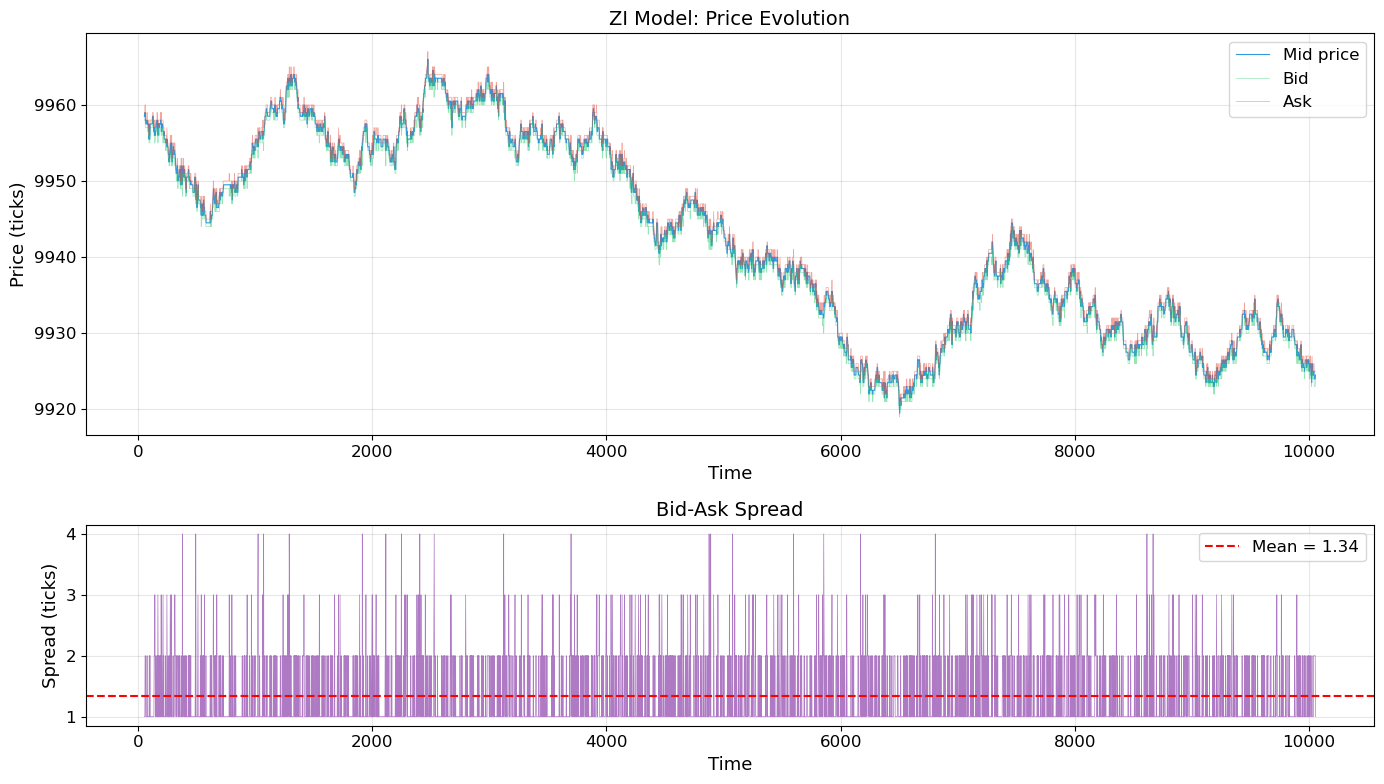

Mean spread: 1.34 ticks (std 0.57)
Share of events with a one-tick spread: 71%


In [3]:
valid = df.dropna(subset=['mid_price'])

fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [2, 1]})
sub = valid.iloc[::max(1, len(valid) // 5000)]
plot_price_series(sub['time'].values, sub['mid_price'].values,
                  bid_prices=sub['best_bid'].values, ask_prices=sub['best_ask'].values, ax=axes[0])
axes[0].set_title('ZI Model: Price Evolution')
plot_spread_timeseries(sub['time'].values, sub['spread'].values, ax=axes[1])
plt.tight_layout()
plt.show()

spread = valid['spread']
print(f"Mean spread: {spread.mean():.2f} ticks (std {spread.std():.2f})")
print(f"Share of events with a one-tick spread: {(spread == 1).mean():.0%}")
findings['Mean spread'] = f"{spread.mean():.2f} ticks"

## 3. Emergent Spread

Gould et al. summarize Smith et al. (2003) this way: *"Guided by dimensional analysis, they constructed simple, closed-form estimators for a variety of LOB properties—such as the mean spread, mean depth available at a given price, and mid-price diffusion—in terms of only the lot size σ and the Poisson processes' arrival rates."*

Dimensional analysis already constrains the answer. Measure prices in ticks and sizes in lots: $\mu$ is in lots per unit time, $\lambda$ in lots per tick per unit time and $\delta$ per unit time. The only combination of the rates with units of price is

$$p_c = \mu / \lambda,$$

and the cancellation rate can only enter through a dimensionless ratio such as $\epsilon = \delta\sigma/\mu$, where $\sigma$ is the order size. So the mean spread must take the form $s = p_c\, f(\epsilon)$, up to corrections from the finite tick and the finite window $L$. Three checks follow:

1. Multiplying every rate by the same factor only changes the unit of time, so it must leave the spread unchanged. Any formula that fails this test cannot be right — for example $\sqrt{\mu/(\lambda\delta)}$, whose value changes with the time unit.
2. At fixed $\epsilon$, $s/p_c$ should settle to a constant once the tick is small compared with $p_c$.
3. $s/p_c$ can still depend on $\epsilon$.

In [4]:
# Check 1: a change of time units. Multiply every rate by 10.
spreads = {}
for k in (1, 10):
    m = SmithFarmerModel(mu=1.0 * k, lam=0.5 * k, delta=0.1 * k, price_range=50, initial_mid=10000)
    _, d = run_model(m, n_events=50_000)
    spreads[k] = d['spread'].mean()
    print(f"rates x{k:>2}: simulated mean spread {spreads[k]:.4f} ticks; "
          f"sqrt(mu / (lambda * delta)) = {np.sqrt(m.mu / (m.lam * m.delta)):.2f}")

invariant = bool(np.isclose(spreads[1], spreads[10]))
print(f"\nSimulated spread unchanged by the change of units: {invariant}")
findings['Spread unchanged by a change of time units'] = str(invariant)

rates x 1: simulated mean spread 1.3398 ticks; sqrt(mu / (lambda * delta)) = 4.47


rates x10: simulated mean spread 1.3398 ticks; sqrt(mu / (lambda * delta)) = 1.41

Simulated spread unchanged by the change of units: True


In [5]:
# Check 2: hold eps = delta * sigma / mu = 0.1 and shrink the tick relative to p_c = mu / lambda.
# The window grows with p_c (L = 25 p_c), so it never cuts off the order flow.
rows = []
for p_c in (1, 2, 4, 8, 16):
    m = SmithFarmerModel(mu=1.0, lam=1.0 / p_c, delta=0.1, price_range=25 * p_c, initial_mid=10000)
    _, d = run_model(m, n_events=60_000, warmup=15_000)
    rows.append({'p_c = mu / lambda': p_c, 'mean spread': d['spread'].mean(),
                 's / p_c': d['spread'].mean() / p_c})
pc_sweep = pd.DataFrame(rows)
print(pc_sweep.round(3).to_string(index=False))

last, previous = pc_sweep['s / p_c'].iloc[-1], pc_sweep['s / p_c'].iloc[-2]
change = abs(last / previous - 1)
if change < 0.15:
    verdict = (f"s / p_c settles near {last:.2f} once the tick is small relative to p_c "
               f"(the last two values differ by {change:.0%}), so the spread scales with mu / lambda")
else:
    verdict = f"s / p_c has not settled (the last two values differ by {change:.0%})"
print("\n" + verdict)
findings['Spread scaling'] = verdict

 p_c = mu / lambda  mean spread  s / p_c
                 1        1.043    1.043
                 2        1.344    0.672
                 4        2.085    0.521
                 8        3.572    0.446
                16        6.724    0.420

s / p_c settles near 0.42 once the tick is small relative to p_c (the last two values differ by 6%), so the spread scales with mu / lambda


In [6]:
# Check 3: hold p_c = 4 ticks and vary eps.
rows = []
for eps in (0.025, 0.05, 0.1, 0.2, 0.4):
    m = SmithFarmerModel(mu=1.0, lam=0.25, delta=eps, price_range=100, initial_mid=10000)
    _, d = run_model(m, n_events=60_000, warmup=20_000)
    rows.append({'eps = delta * sigma / mu': eps, 'mean spread': d['spread'].mean(),
                 's / p_c': d['spread'].mean() / 4})
eps_sweep = pd.DataFrame(rows)
print(eps_sweep.round(3).to_string(index=False))

if np.all(np.diff(eps_sweep['s / p_c']) > 0):
    verdict = (f"s / p_c rises with eps, from {eps_sweep['s / p_c'].iloc[0]:.2f} to "
               f"{eps_sweep['s / p_c'].iloc[-1]:.2f}: faster cancellation thins the book and widens the spread")
else:
    verdict = "s / p_c does not change monotonically with eps over this range"
print("\n" + verdict)
findings['Spread vs cancellation'] = verdict

 eps = delta * sigma / mu  mean spread  s / p_c
                    0.025        1.616    0.404
                    0.050        1.674    0.418
                    0.100        2.044    0.511
                    0.200        2.493    0.623
                    0.400        3.238    0.809

s / p_c rises with eps, from 0.40 to 0.81: faster cancellation thins the book and widens the spread


## 4. Depth Profile

Empirically, *"Mean relative depth profiles have been reported to exhibit a hump shape in a wide range of markets"* (Section 4.4): depth is lower at the best quote than a few ticks away, then thins out further from the quotes. The claim is about a time average, so we average the recorded snapshots rather than look at a single one.

Far from the quotes, each tick of the ZI book behaves like an $M/M/\infty$ queue: orders arrive at rate $\lambda$ and each lives for an exponential time with mean $1/\delta$, so the mean depth there should be $\lambda/\delta$.

We call a profile a *hump* if its deepest point beyond the best quote is at least 5% above the depth at the quote **and** the far end falls at least 20% below that peak; if it rises but does not fall again, it *rises to a plateau*.

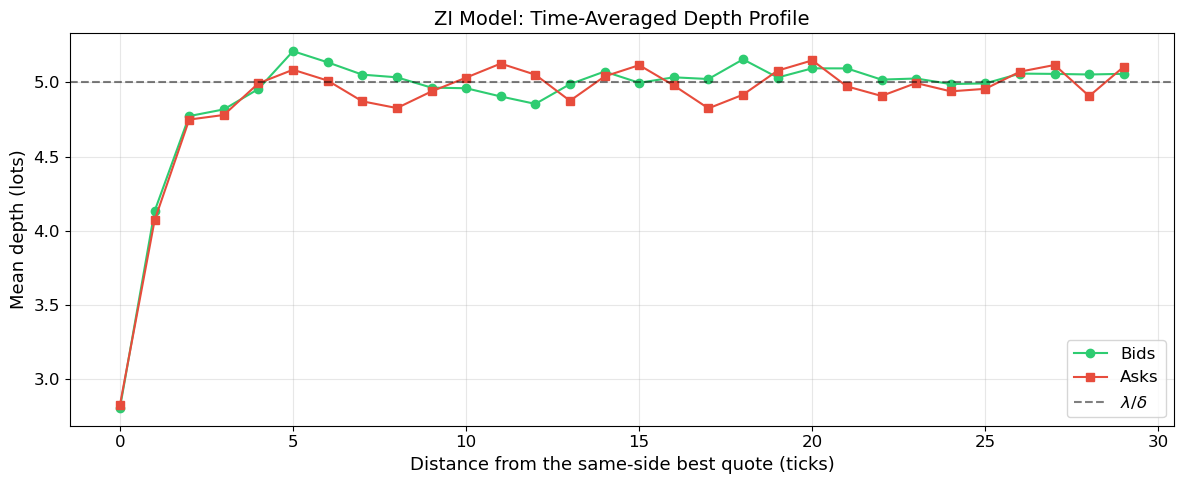

Depth at the best quote: 2.82 lots; deepest level +83% above it; far end 1% below that peak
Shape: rises to a plateau (no hump)
Mean depth 15-29 ticks out: 5.02 lots (lambda / delta = 5.00)


In [7]:
deltas, bid_depth, ask_depth = mean_depth_profile(sim.snapshots, n_ticks=30)
profile = (bid_depth + ask_depth) / 2

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(deltas, bid_depth, 'o-', color='#2ecc71', label='Bids')
ax.plot(deltas, ask_depth, 's-', color='#e74c3c', label='Asks')
ax.axhline(model.lam / model.delta, color='black', linestyle='--', alpha=0.5,
           label=r'$\lambda / \delta$')
ax.set_xlabel('Distance from the same-side best quote (ticks)')
ax.set_ylabel('Mean depth (lots)')
ax.set_title('ZI Model: Time-Averaged Depth Profile')
ax.legend()
plt.tight_layout()
plt.show()

shape, rise, fall, peak = classify_depth_profile(profile)
label = {'hump': f'hump, peaking {peak} ticks from the best quote',
         'plateau': 'rises to a plateau (no hump)',
         'best quote': 'deepest at the best quote (no hump)'}[shape]
far = profile[15:].mean()
print(f"Depth at the best quote: {profile[0]:.2f} lots; deepest level {rise:+.0%} above it; "
      f"far end {fall:.0%} below that peak")
print(f"Shape: {label}")
print(f"Mean depth 15-29 ticks out: {far:.2f} lots (lambda / delta = {model.lam / model.delta:.2f})")
findings['Depth profile'] = label

## 5. Return Distribution

Section 4.7.1 of the paper: *"Over all timescales ranging from seconds to days, unconditional distributions of mid-price returns have been reported to display tails that are heavier than a normal distribution (i.e. they have positive excess kurtosis)."* It also notes that at longer timescales return distributions have been reported to come increasingly close to a normal distribution: *"This behaviour is often called aggregational Gaussianity."*

Returns need care in a tick-based model. Most events (cancellations, and orders placed away from the quotes) leave the mid-price unchanged, so returns over a handful of events are mostly exactly zero, and that alone inflates the kurtosis. We therefore measure log returns over blocks of $K$ events and watch how the picture changes as $K$ grows.

In [8]:
mid = valid['mid_price'].to_numpy(dtype=float)
print(f"Share of events that move the mid-price: {np.mean(np.diff(mid) != 0):.2%}\n")

rows = []
for k in (50, 250, 1_000, 5_000):
    r = event_time_returns(mid, k)
    rows.append({'K (events)': k, 'returns': len(r), 'zero returns': np.mean(r == 0),
                 'excess kurtosis': stats.kurtosis(r)})
aggregation = pd.DataFrame(rows)
print(aggregation.to_string(index=False, formatters={'zero returns': '{:.0%}'.format,
                                                     'excess kurtosis': '{:.2f}'.format}))

Share of events that move the mid-price: 0.70%

 K (events)  returns zero returns excess kurtosis
         50    19999          76%            7.70
        250     3999          48%            2.00
       1000      999          26%            0.34
       5000      199          15%           -0.06


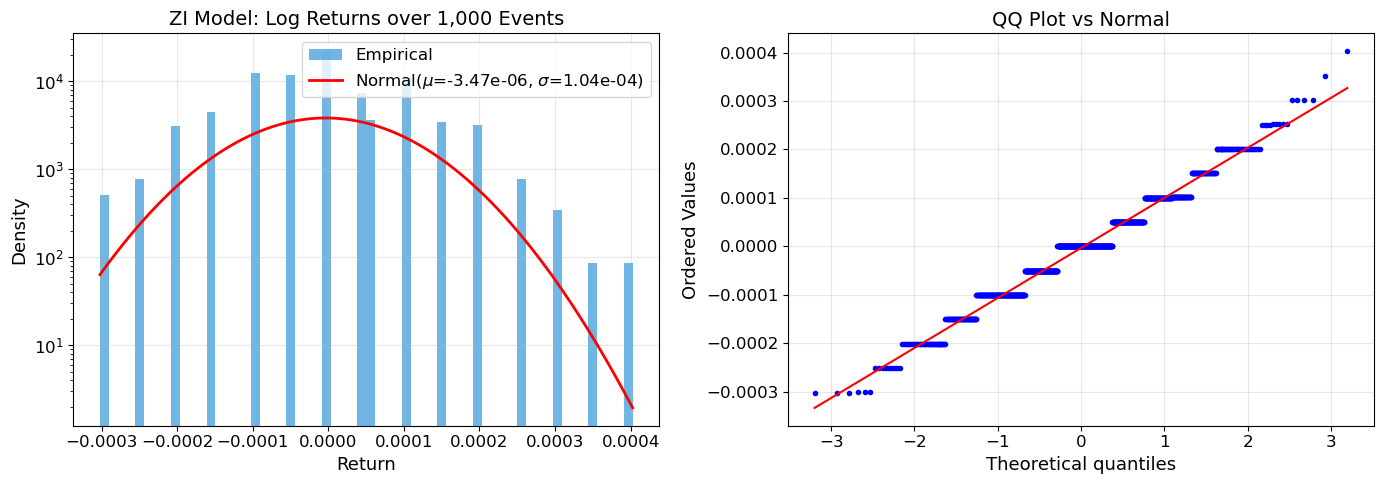

Excess kurtosis over 1,000 events: 0.34 (Gaussian data would give 0 ± 0.15)
Verdict: close to Gaussian once aggregated (excess kurtosis 7.7 at K=50, -0.06 at K=5,000); at K=50, 76% of returns are exactly zero, which inflates the kurtosis


In [9]:
K = 1_000
returns = event_time_returns(mid, K)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_return_distribution(returns, n_bins=60, ax=axes[0])
axes[0].set_title(f'ZI Model: Log Returns over {K:,} Events')
stats.probplot(returns, dist='norm', plot=axes[1])
axes[1].set_title('QQ Plot vs Normal')
axes[1].get_lines()[0].set_markersize(3)
plt.tight_layout()
plt.show()

kurt = stats.kurtosis(returns)
se = np.sqrt(24 / len(returns))  # standard error of excess kurtosis for Gaussian data
first, last = aggregation['excess kurtosis'].iloc[0], aggregation['excess kurtosis'].iloc[-1]
zero_first = aggregation['zero returns'].iloc[0]
print(f"Excess kurtosis over {K:,} events: {kurt:.2f} (Gaussian data would give 0 ± {se:.2f})")
if abs(kurt) < 3 * se:
    verdict = f"close to Gaussian once aggregated (excess kurtosis {first:.1f} at K=50, {last:.2f} at K=5,000)"
    if zero_first > 0.5:
        verdict += f"; at K=50, {zero_first:.0%} of returns are exactly zero, which inflates the kurtosis"
else:
    verdict = f"heavier-tailed than Gaussian even over {K:,} events (excess kurtosis {kurt:.2f})"
print("Verdict:", verdict)
findings['Return tails'] = verdict

## 6. Autocorrelation of Returns

Section 4.7.4 of the paper: *"Several studies have reported that return series lacked significant autocorrelation, except for weakly negative autocorrelation on very short timescales."*

The ZI mid-price has a mechanical reason to reverse: when a market order empties the best quote, the spread widens, and new limit orders tend to land in the gap and pull the mid back. We look at successive mid-price changes (skipping events that leave it unchanged) and at the aggregated returns. Dashed lines mark the 95% band for white noise of the same length.

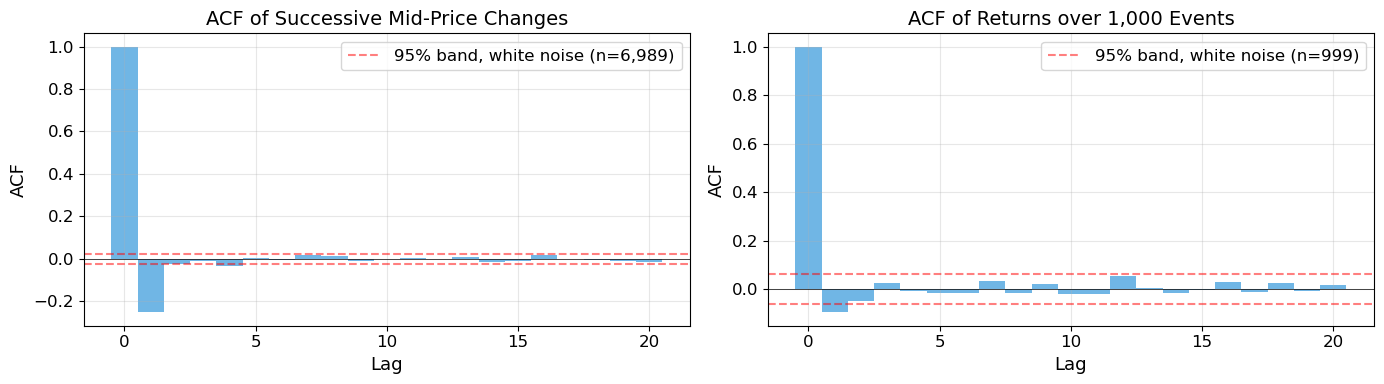

Lag-1 ACF of successive mid-price changes: -0.254 (band ±0.023, n=6,989) -> significantly negative
Lag-1 ACF of returns over 1,000 events: -0.096 (band ±0.062, n=999) -> significantly negative


In [10]:
changes = np.diff(mid)
changes = changes[changes != 0]
acf_changes = compute_acf(changes, max_lag=20)
acf_returns = compute_acf(returns, max_lag=20)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(acf_changes, title='ACF of Successive Mid-Price Changes', ax=axes[0], n=len(changes))
plot_acf(acf_returns, title=f'ACF of Returns over {K:,} Events', ax=axes[1], n=len(returns))
plt.tight_layout()
plt.show()

for label, acf, n in (('successive mid-price changes', acf_changes, len(changes)),
                      (f'returns over {K:,} events', acf_returns, len(returns))):
    band = white_noise_band(n)
    call = ('significantly negative' if acf[1] < -band else
            'significantly positive' if acf[1] > band else 'not significant')
    print(f"Lag-1 ACF of {label}: {acf[1]:+.3f} (band ±{band:.3f}, n={n:,}) -> {call}")
findings['Lag-1 return autocorrelation'] = f"{acf_returns[1]:+.3f} over {K:,} events"

## 7. Volatility Clustering

Section 4.7.2: *"Time series of absolute or square mid-price returns have been reported to display long memory ... over timescales of weeks or even months."* In other words, large moves tend to follow large moves. We measure this with the autocorrelation of $|r|$, and also of the *ranks* of $|r|$, which a handful of extreme returns cannot dominate.

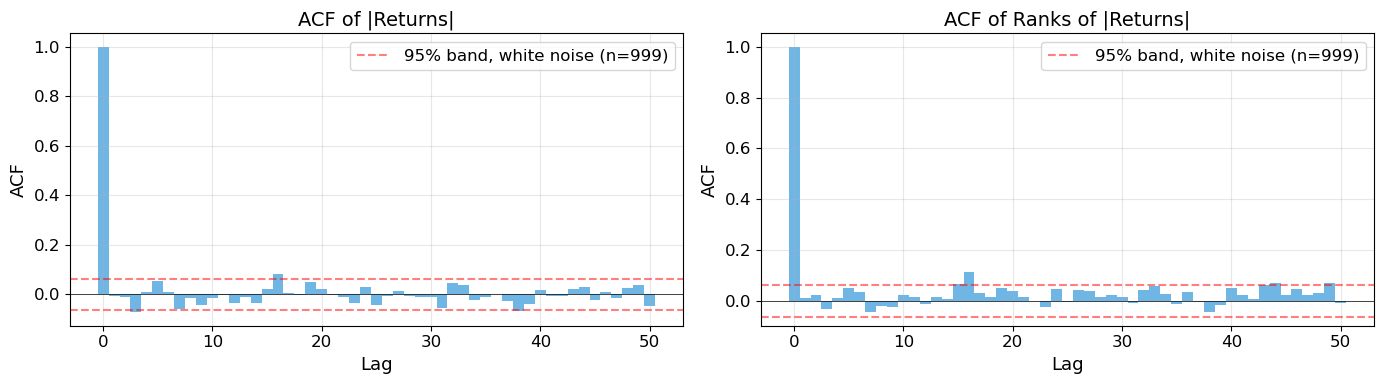

Rank ACF of |r| at lag 1: +0.012 (band ±0.062); lags 1-10 outside the band: 0% (5% expected by chance)
Volatility clustering in 1,000-event returns: not detected


In [11]:
acf_abs = compute_acf(np.abs(returns), max_lag=50)
acf_rank = compute_rank_volatility_acf(returns, max_lag=50)
band = white_noise_band(len(returns))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(acf_abs, title='ACF of |Returns|', ax=axes[0], n=len(returns))
plot_acf(acf_rank, title='ACF of Ranks of |Returns|', ax=axes[1], n=len(returns))
plt.tight_layout()
plt.show()

outside = np.mean(np.abs(acf_rank[1:11]) > band)
print(f"Rank ACF of |r| at lag 1: {acf_rank[1]:+.3f} (band ±{band:.3f}); "
      f"lags 1-10 outside the band: {outside:.0%} (5% expected by chance)")
verdict = 'detected' if acf_rank[1] > band else 'not detected'
print(f"Volatility clustering in {K:,}-event returns: {verdict}")
findings['Volatility clustering'] = verdict

## 8. What the ZI Model Does and Does Not Reproduce

The scorecard sets the measurements above against the empirical findings in Section 4 of the paper. The last two rows are fixed by construction: ZI order flow has no memory and places orders uniformly.

In [12]:
scorecard = pd.DataFrame([
    ('Heavy-tailed returns', 'Yes, from seconds to days (Sec. 4.7.1)', findings['Return tails']),
    ('Volatility clustering', 'Yes (Sec. 4.7.2)', findings['Volatility clustering']),
    ('Return autocorrelation', 'Weakly negative at very short lags (Sec. 4.7.4)',
     findings['Lag-1 return autocorrelation']),
    ('Mean depth profile', 'Hump-shaped in many markets (Sec. 4.4)', findings['Depth profile']),
    ('Long memory in order signs', 'Yes (Sec. 4.7.3)', 'No: signs are independent by construction'),
    ('Power-law relative prices', 'Yes (Sec. 4.2)', 'No: placement is uniform by construction'),
], columns=['Property', 'Real markets', 'ZI model (measured above)'])
display(scorecard)

print("Spread findings:")
for key in ('Mean spread', 'Spread unchanged by a change of time units', 'Spread scaling', 'Spread vs cancellation'):
    print(f"  {key}: {findings[key]}")

,Property,Real markets,ZI model (measured above)
0,Heavy-tailed returns,"Yes, from seconds to days (Sec. 4.7.1)","close to Gaussian once aggregated (excess kurtosis 7.7 at K=50, -0.06 at K=5,000); at K=50, 76% of returns are exactly zero, which inflates the kurtosis"
1,Volatility clustering,Yes (Sec. 4.7.2),not detected
2,Return autocorrelation,Weakly negative at very short lags (Sec. 4.7.4),"-0.096 over 1,000 events"
3,Mean depth profile,Hump-shaped in many markets (Sec. 4.4),rises to a plateau (no hump)
4,Long memory in order signs,Yes (Sec. 4.7.3),No: signs are independent by construction
5,Power-law relative prices,Yes (Sec. 4.2),No: placement is uniform by construction


Spread findings:
  Mean spread: 1.34 ticks
  Spread unchanged by a change of time units: True
  Spread scaling: s / p_c settles near 0.42 once the tick is small relative to p_c (the last two values differ by 6%), so the spread scales with mu / lambda
  Spread vs cancellation: s / p_c rises with eps, from 0.40 to 0.81: faster cancellation thins the book and widens the spread


## Summary

The ZI model shows how much LOB structure comes from mechanics alone: the spread and the depth profile emerge from independent order flows, and dimensional analysis predicts how the spread scales with the rates. The scorecard records which empirical regularities that is enough for in this run; the ones it misses point to what richer models have to add.

**Next:** Notebook 04 catalogs the empirical stylized facts that any serious LOB model should reproduce.